<div dir="rtl" style="text-align:right">
<h1 id="دفتر-المحاضرة-الكامل-3">دفتر المحاضرة الكامل — 3</h1>
<p dir="rtl" style="text-align:right">نقرأ الشرح، ونتوقّع النتيجة، ثم ننفّذ الخلية التالية ونفسّر مخرجاتها قبل أن نتابع. نستخدم <strong>Restart Kernel and Run All</strong> لنتأكد من أن العمل لا يعتمد على جلسة سابقة. تبقى الشروح والاشتقاقات الرياضية والافتراضات الفيزيائية من الفصل محيطة بالخلايا.</p>
</div>

<div dir="rtl" style="text-align:right">
<h2 id="تهيئة-الدفتر-المرفقة">تهيئة الدفتر المرفقة</h2>
<p dir="rtl" style="text-align:right">نختار نواة <strong>Julia 1.12</strong> ونفتح الدفتر من مجلد فصله. تعثر هذه التهيئة المرفقة على بيئة المقرر المسجّلة وتنشئ مجلدًا منفصلًا للأشكال المصدّرة؛ وهي لا تثبّت أي حزم. أوامر التهيئة بنية تحتية، وليست مادة لغوية جديدة تخضع للتقييم.</p>
</div>

In [1]:
import Pkg
course_root = abspath("../..")
if !isfile(joinpath(course_root, "Project.toml"))
    error("Start this notebook from its week folder, e.g. week-1/notebooks")
end
ENV["PHYSPROG_HOME"] = course_root   # let data-reading code find the course folder
Pkg.activate(course_root; io=devnull)
output_dir = get(ENV, "COURSE_NOTEBOOK_OUTPUT", joinpath(pwd(), "generated", "lecture-ar"))
mkpath(output_dir)
println("Course environment active; figure output directory ready.")

Course environment active; figure output directory ready.


<div dir="rtl" style="text-align:right">
<h1 id="الحلقات-والمتجهات-والحركة-المرصودة">الحلقات والمتجهات والحركة المرصودة</h1>
<p dir="rtl" style="text-align:right">تسأل مسائل فيزيائية كثيرة عن الحساب نفسه في أزمنة أو مواضع كثيرة. ونجعل الآن التكرار صريحًا ونخزّن تاريخه في متجهات. المتجه مجموعة مرتبة من القيم، والحلقة تكرّر كتلة من التعليمات، ومعًا تعطياننا طريقةً نخطو بها بنموذج إلى الأمام في الزمن. وهدفنا أن نفهم أيّ التعليمات تتكرر، وما الذي يتغير في كل خطوة، وما الدليل الذي يخبرنا أن نتوقف. ونستدعي أدوات قائمة، أما تعريف دوالنا فيعود إلى الأسبوع الخامس.</p>
<h2 id="المتجهات-تخزن-تواريخا-مرتبة">المتجهات تخزّن تواريخًا مرتبة</h2>
<h3 id="إنشاء-المتجهات">إنشاء المتجهات</h3>
<p dir="rtl" style="text-align:right">المتجه مجموعة مرتبة تُكتب بأقواس مربعة. ويمكننا كتابة متجه مباشرة، أو البدء بمتجه فارغ، أو طلب متجه جاهز من أصفار أو وحدات:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [2]:
v = [10, 20, 30, 40]
empty_int = Int[]
println(v)
println(empty_int)
println(zeros(5))
println(ones(4))
println(collect(1:5))
println(range(0, 1; length=6))

[10, 20, 30, 40]
Int64[]
[0.0, 0.0, 0.0, 0.0, 0.0]
[1.0, 1.0, 1.0, 1.0]
[1, 2, 3, 4, 5]
0.0:

0.2:1.0


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">[10, 20, 30, 40]
Int64[]
[0.0, 0.0, 0.0, 0.0, 0.0]
[1.0, 1.0, 1.0, 1.0]
[1, 2, 3, 4, 5]
0.0:0.2:1.0</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">التعبير <code dir="ltr">1:5</code> هو <em>مدى</em> (range)، لا متجه: فهو يصف القيم من 1 إلى 5 دون تخزينها. ونستدعي <code dir="ltr">collect</code> عندما نريد متجهًا فعليًا. ويظهر المدى <code dir="ltr">0:0.2:1.0</code> الناتج عن <code dir="ltr">range(0, 1; length=6)</code> كمدى لأن ست نقاط متباعدة بالتساوي من 0 إلى 1 تفصل بينها 0.2. ويعطي <code dir="ltr">zeros(5)</code> متجهًا من خمسة أصفار بفاصلة عائمة؛ ويعطي <code dir="ltr">ones(4)</code> أربع وحدات. و <code dir="ltr">Int[]</code> متجه فارغ ستكون عناصره أعدادًا صحيحة. ومصفوفات <code dir="ltr">Julia</code> قابلة للتغيير: يمكننا تغيير العناصر أو الطول بعد الإنشاء، كما سنرى قريبًا.</p>
<h3 id="الفهرسة-والتقطيع">الفهرسة والتقطيع</h3>
<p dir="rtl" style="text-align:right">تبدأ المتجهات العادية في <code dir="ltr">Julia</code> من الفهرس 1. ويحدد الفهرس موضعًا لا القيمة المخزنة فيه؛ و <code dir="ltr">end</code> داخل تعبير فهرسة يحدد الموضع الأخير.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [3]:
v = [10, 20, 30, 40, 50]
println(v[1])
println(v[end])
println(v[2:4])
println(v[2:end])
v[2:3] = [99, 88]
println(v[[1, 3, 5]])
indices = [2, 3]
println(v[indices])
println(v)

10
50
[20, 30, 40]
[20, 30, 40, 50]
[10, 88, 50]
[99, 88]
[10, 99, 88, 40, 50]


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">10
50
[20, 30, 40]
[20, 30, 40, 50]
[10, 88, 50]
[99, 88]
[10, 99, 88, 40, 50]</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تشمل التقطيعة مثل <code dir="ltr">v[2:4]</code> الطرفين. ويمكننا الإسناد إلى تقطيعة، ويمكننا تحديد مواضع متعددة دفعة واحدة بتمرير متجه من المواضع إلى الفهرس. وتخبرنا الدوال <code dir="ltr">length(v)</code> و<code dir="ltr">firstindex(v)</code> و<code dir="ltr">lastindex(v)</code> بعدد العناصر وبأول وآخر موضع صالح.</p>
<h4 id="التقطيعة-نسخة-والاسم-البديل-هو-المتجه-نفسه">التقطيعة نسخة؛ والاسم البديل هو المتجه نفسه</h4>
<p dir="rtl" style="text-align:right">بالنسبة لمتجه عادي، ينسخ <code dir="ltr">part = height[2:3]</code> تلك العناصر. وتغيير <code dir="ltr">part[1]</code> لا يغير <code dir="ltr">height</code>. وفي المقابل، يجعل <code dir="ltr">same = height</code> اسمًا ثانيًا يشير إلى المتجه نفسه؛ وتغيير <code dir="ltr">same[1]</code> يغير الكائن المشترك. وينشئ <code dir="ltr">copy(a)</code> نسخة حقيقية مستقلة. أما <em>المنظر</em> (view) فيشارك التخزين مع الأصل دون نسخ: يسمح لنا <code dir="ltr">@view a[1:2]</code> بقراءة وكتابة أول عنصرين من <code dir="ltr">a</code> عبر اسم جديد. وعلامة <code dir="ltr">@</code> تدل على ماكرو، وهو تحويل صغير مدمج للتعبير الذي يليه؛ نستخدمه هنا فقط لطلب المنظر، ولا نحتاج إلى كتابة ماكروهات بأنفسنا.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [4]:
a = [1, 2, 3]
b = a
c = a[1:2]
d = copy(a)
e = @view a[1:2]
a[1] = 2
println("a[1]=", a[1], " b[1]=", b[1], " c[1]=", c[1], " d[1]=", d[1], " e[1]=", e[1])

a[1]=2 b[1]=2 c[1]=1 d[1]=1 e[1]=2


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">a[1]=2 b[1]=2 c[1]=1 d[1]=1 e[1]=2</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">يتبع الاسم البديل <code dir="ltr">b</code> والمنظر <code dir="ltr">e</code> التغيير؛ أما النسخة <code dir="ltr">d</code> والتقطيعة <code dir="ltr">c</code> فلا تتبعانه. ويعتمد السلوك الذي نريده على ما إذا كنا نقصد التخزين نفسه أم لقطة منه.</p>
<h3 id="تغيير-متجه">تغيير متجه</h3>
<p dir="rtl" style="text-align:right">علامة التعجب <code dir="ltr">!</code> في نهاية اسم دالة هي اصطلاح <code dir="ltr">Julia</code> للعملية المغيِّرة: فقد تغيّر الوسيط نفسه. تضيف <code dir="ltr">push!</code> قيمة واحدة، وتضيف <code dir="ltr">append!</code> كل عنصر من مجموعة، وتزيل <code dir="ltr">pop!</code> العنصر الأخير وتعيده. وتغيّران <code dir="ltr">insert!</code> و<code dir="ltr">deleteat!</code> موضعًا مختارًا.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [5]:
v = [1, 2, 3]
push!(v, 4); println(v)
append!(v, [5, 6]); println(v)
pop!(v); println(v)
insert!(v, 2, 99); println(v)
deleteat!(v, 2); println(v)
w = vcat(v, [7, 8]); println(w); println(v)
w2 = [v; 7; 8]; println(w2)

[1, 2, 3, 4]
[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5]
[1, 99, 2, 3, 4, 5]
[1, 2, 3, 4, 5]
[1, 2, 3, 4, 5, 7, 8]
[1, 2, 3, 4, 5]


[1, 2, 3, 4, 5, 7, 8]


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">[1, 2, 3, 4]
[1, 2, 3, 4, 5, 6]
[1, 2, 3, 4, 5]
[1, 99, 2, 3, 4, 5]
[1, 2, 3, 4, 5]
[1, 2, 3, 4, 5, 7, 8]
[1, 2, 3, 4, 5]
[1, 2, 3, 4, 5, 7, 8]</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">لاحظوا الفرق: تضيف <code dir="ltr">push!</code> كائنًا واحدًا، وتضيف <code dir="ltr">append!</code> كل عنصر من مجموعة، بينما يبني <code dir="ltr">vcat</code> متجهًا جديدًا موصولًا ويترك <code dir="ltr">v</code> دون تغيير. وتصل الصيغة القوسية <code dir="ltr">[v; 7; 8]</code> بالطريقة نفسها. وفي أمثلة الحلقات القادمة سننمي التواريخ بـ <code dir="ltr">push!</code>، وهي الطريقة الطبيعية لتخزين تسلسل عينات أثناء حسابها.</p>
<h3 id="حساب-المتجهات-والدوال-المفيدة">حساب المتجهات والدوال المفيدة</h3>
<p dir="rtl" style="text-align:right">يعمل الحساب على المتجهات عنصرًا عنصرًا، وتلخص بعض الدوال متجهًا كاملًا:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [6]:
a = [1.0, 2.0, 3.0]
b = [4.0, 5.0, 6.0]
println(a + b)
println(2a)
println(sum(a)); println(maximum(a)); println(minimum(a)); println(length(a))
println(a .* b)
println(a .^ 2)
println(sqrt.(a))
using LinearAlgebra
println(dot(a, b))
println(round(norm([1,1]); digits=4))

[5.0, 7.0, 9.0]
[2.0, 4.0, 6.0]
6.0
3.0
1.0


3
[4.0, 10.0, 18.0]
[1.0, 4.0, 9.0]
[1.0, 1.4142135623730951, 1.7320508075688772]
32.0
1.4142


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">[5.0, 7.0, 9.0]
[2.0, 4.0, 6.0]
6.0
3.0
1.0
3
[4.0, 10.0, 18.0]
[1.0, 4.0, 9.0]
[1.0, 1.4142135623730951, 1.7320508075688772]
32.0
1.4142</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تشير النقطة إلى عملية عنصرًا-عنصر: يضرب <code dir="ltr">a .* b</code> العناصر المتطابقة، بينما يكون <code dir="ltr">a * b</code> خطأً لهذه الأشكال. وتعمل المؤثرات المنقوطة عنصرًا عنصرًا، لذا يربّع <code dir="ltr">a .^ 2</code> كل عنصر، ويطبق <code dir="ltr">sqrt.(a)</code> الجذر التربيعي على كل عنصر. وتبلغ <code dir="ltr">sum</code> و<code dir="ltr">maximum</code> و<code dir="ltr">minimum</code> و<code dir="ltr">length</code> عن عدد واحد للمتجه كله. وتوفر الوحدة القياسية <code dir="ltr">LinearAlgebra</code> الجداء السلمي <code dir="ltr">dot(a, b)</code> والطول <code dir="ltr">norm(a)</code>؛ ومثل <code dir="ltr">Statistics</code>، هي جزء من <code dir="ltr">Julia</code> ولا تحتاج إلى تركيب.</p>
<h4 id="تمرين-سريع">تمرين سريع</h4>
<p dir="rtl" style="text-align:right">أنشئوا متجهًا من خمس قيم، واستبدلوا عنصره الثالث، وأضيفوا قيمتين إضافيتين، واحسبوا متوسطه باستخدام <code dir="ltr">sum(v) / length(v)</code>. ثم تحققوا من المتوسط بـ <code dir="ltr">using Statistics; mean(v)</code>.</p>
<h2 id="تكرار-مخطط-حلقة-for">تكرار مخطَّط: حلقة <code dir="ltr">for</code></h2>
<p dir="rtl" style="text-align:right">تكرّر الحلقة كتلة من التعليمات. وتزور حلقة <code dir="ltr">for</code> مجموعة قيم مُعطاة بالترتيب: <code dir="ltr">for value in collection</code>، ثم كتلة، ثم <code dir="ltr">end</code>. وقبل تشغيلها نسرد القيم التي سيأخذها متغير الحلقة. ويبدأ التعليق بالرمز <code dir="ltr">#</code>؛ وهو يشرح خيارًا لقارئ ولا يُنفَّذ.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [7]:
for n in 1:3
    println(n)
end

1
2
3


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">1
2
3</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">يشمل المدى <code dir="ltr">1:3</code> الطرفين. أما الصيغة الأعم <code dir="ltr">start:step:stop</code> فتزور القيم المتفاصلة بالخطوة دون تجاوز حد التوقف. ونستخدم خطوة سالبة للعدّ نحو الأسفل. ولا يُشمَل حد التوقف نفسه إلا عندما تصل إليه المسافة بين القيم.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [8]:
for time in 0:2:10   # s
    println("time = $time s")
end

time = 0 s
time = 2 s
time = 4 s
time = 6 s
time = 8 s
time = 10 s


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">time = 0 s
time = 2 s
time = 4 s
time = 6 s
time = 8 s
time = 10 s</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تُدرج علامة الدولار قيمة في سلسلة نصية. ولحساب بدل اسم مفرد نستخدم <code dir="ltr">$(expression)</code>، كما في <code dir="ltr">println("square = $(n^2)")</code>.</p>
<p dir="rtl" style="text-align:right">ثمة طرق عدة لزيارة عناصر متجه. يمكن لمتغير الحلقة أن يأخذ قيمًا صحيحة، أو القيم نفسها، أو فهارس صالحة، أو زوج فهرس-قيمة:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [9]:
v = [10, 20, 30]
for i in 1:3
    println(i)
end
for x in v
    println(x)
end
for i in eachindex(v)
    println("index = ", i, ", value = ", v[i])
end
for (i, x) in enumerate(v)
    println(i, " => ", x)
end

1


2
3
10
20
30
index = 1, value = 10
index = 2, value = 20
index = 3, value = 30
1 => 10
2 => 20
3 => 30


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">1
2
3
10
20
30
index = 1, value = 10
index = 2, value = 20
index = 3, value = 30
1 =&gt; 10
2 =&gt; 20
3 =&gt; 30</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">يعتمد اختيار الصيغة على ما يحتاج إليه الجسم. فعندما تكون القيم فقط هي المهمة، يكون <code dir="ltr">for x in v</code> أوضح. وعندما نفهرِ أو نعدّل عناصر، يوفر <code dir="ltr">eachindex(v)</code> الفهارس الصالحة لذلك المجموع، فلا نضطر إلى افتراض مدى فهارس معين. ويزود <code dir="ltr">enumerate</code> عدّادًا إلى جانب كل عنصر؛ وعدّاده هو الموضع العادي الذي يبدأ من 1 هنا، وهذا كل ما نحتاجه.</p>
<h4 id="المراكم-قيمة-تحمل-بين-التكرارات">المراكم قيمة تُحمَل بين التكرارات</h4>
<p dir="rtl" style="text-align:right">لجمع قيم عدة، نهيّئ مجموعًا، ونضيف مساهمة واحدة، ونحتفظ بالمجموع الجديد للخطوة التالية. وعلينا التهيئة خارج الكتلة المكررة؛ فإعادة ضبطها داخلها ستُهدر المساهمات السابقة. ويسجّل العدّاد كم خطوة نفّذنا، بينما يسجّل المراكم نتيجتها المجمّعة. وتجمّع الأمثلة أدناه بياناتها في كتلة <code dir="ltr">begin ... end</code>، فتقرأ كل دالة كوحدة واحدة ويمكن لصقها وتشغيلها كما هي.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [10]:
begin v = [3, 5, 8, 2]
    total = 0
    for x in v
        total += x
    end
    println(total)
    println(sum(v))
end

18
18


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">18
18</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تعيد الحلقة إنتاج <code dir="ltr">sum(v)</code> بإضافة واحدة في كل مرة. وهذا هو الهيكل الأساسي لمعظم عمليات التجميع في هذا المقرر: ابدأ بقيمة حيادية، وادمج عنصرًا واحدًا في كل تكرار، واحتفظ بالنتيجة للخطوة التالية. والمضروب هو النمط نفسه مع ضرب بدل الجمع:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [11]:
begin f = 1
    for n in 1:5
        f = f * n
    end
    println(f)
end

120


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">120</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">العدّاد مراكم للخطوات التي تحقق شرطًا:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [12]:
begin v = [-2, 3, 0, 7, -1]
    count_positive = 0
    for x in v
        if x > 0
            count_positive += 1
        end
    end
    println(count_positive)
end

2


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">2</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">إيجاد قيمة عظمى دون <code dir="ltr">maximum</code> يستخدم مراكمًا يتحسن فقط:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [13]:
begin v = [4, 9, 2, 7]
    largest = v[1]
    for x in v
        if x > largest
            largest = x
        end
    end
    println(largest)
end

9


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">9</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">بناء متجه من مجاميع جارية يجمع مراكمًا مع <code dir="ltr">push!</code>:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [14]:
begin v = [2, 3, 5, 7]
    running = 0
    cumulative = Int[]
    for x in v
        running += x
        push!(cumulative, running)
    end
    println(cumulative)
    println(cumsum(v))
end

[2, 5, 10, 17]
[2, 5, 10, 17]


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">[2, 5, 10, 17]
[2, 5, 10, 17]</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">هنا يسجّل المتجه <code dir="ltr">cumulative</code> الحالة في كل خطوة، لا الأخيرة فقط. وهذا هو النمط الذي سنستخدمه لتخزين مسار: ادفع كل عينة جديدة أثناء حسابها، وقارن بنتيجة معلومة.</p>
<p dir="rtl" style="text-align:right">عملية متجهية شائعة هي الجداء السلمي، التي تستخدم أيضًا مراكمًا عبر فهارس متطابقة:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [15]:
using LinearAlgebra
begin
    a = [1.0, 2.0, 3.0]
    b = [4.0, 5.0, 6.0]
    s = 0.0
    for i in eachindex(a, b)
        s += a[i] * b[i]
    end
    println(s)              # 32.0
    println(dot(a, b), " ", a⋅b)   # 32.0 32.0
end

32.0
32.0 32.0


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">32.0
32.0 32.0</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">يجب أن يكون للمتجهين الطول نفسه حتى تكون الحلقة منطقية؛ وهذا بالضبط ما يشترطه <code dir="ltr">eachindex(a, b)</code>. وتجميع مجموع بـ <code dir="ltr">s += a[i] * b[i]</code> هو النسخة اليدوية للجداء السلمي.</p>
<h2 id="الملخصات-المتوسط-والانحراف-المعياري-للعينة">الملخصات: المتوسط والانحراف المعياري للعينة</h2>
<h4 id="الموقع-والانتشار-يجيبان-عن-سؤالين-مختلفين">الموقع والانتشار يجيبان عن سؤالين مختلفين</h4>
<p dir="rtl" style="text-align:right">بالنسبة لـ <span dir="ltr" class="math inline">\(n\)</span> مشاهدة <span dir="ltr" class="math inline">\(q_i\)</span>، المتوسط هو <span dir="ltr" class="math inline">\(\bar q=\sum_iq_i/n\)</span>. والانحراف المعياري المصحح للعينة هو <span dir="ltr" class="math display">\[s=\sqrt{\frac{1}{n-1}\sum_{i=1}^n(q_i-\bar q)^2},\qquad n\ge2.\]</span> ولكل منهما وحدات <span dir="ltr" class="math inline">\(q\)</span>. يحدد المتوسط موقع العينة، ويقيس الانحراف المعياري انتشارها. ولا يستبعد رقم عشري أصغر ولا انتشار صغير خطأً منهجيًا في القياس. وتفسير <span dir="ltr" class="math inline">\(s/\sqrt n\)</span> بعدم يقين للمتوسط يتطلب افتراضات إضافية عن قياسات متكررة مستقلة.</p>
<p dir="rtl" style="text-align:right"><code dir="ltr">Statistics</code> وحدة مكتبة قياسية تأتي مع <code dir="ltr">Julia</code>، فلا تحتاج إلى تركيب حزمة. ويجعل الإعلان <code dir="ltr">using Statistics</code> الدالتين <code dir="ltr">mean</code> و<code dir="ltr">std</code> متاحتين:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [16]:
using Statistics
measurements = [1.0, 2.0, 3.0]   # m
println(mean(measurements))
println(std(measurements))

2.0
1.0


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">2.0
1.0</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تستخدم <code dir="ltr">std</code> الافتراضية التصحيح أعلاه، وتعمل الدالتان على متجه كامل. والمسار ليس تلقائيًا مجموعة قياسات متكررة مستقلة؛ فالانتشار في المواضع لا يقدّر بذاته عدم يقين آلي.</p>
<h2 id="تكرار-متحكم-فيه-بشرط-while">تكرار متحكم فيه بشرط: <code dir="ltr">while</code></h2>
<p dir="rtl" style="text-align:right">تفحص حلقة <code dir="ltr">while</code> شرطها قبل كل تكرار. ونحدد تهيئتها وشرطها وتحديثها وحجة إنهائها. وقد تُنفَّذ صفر مرات. ويغادر <code dir="ltr">break</code> الحلقة الأقرب فورًا؛ وفي بحث محدود يسمح لنا بالتوقف عند أول نجاح.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [17]:
for n in 1:10
    if n^2 >= 20
        println("first square at least 20 is $(n^2)")
        break
    end
end

first square at least 20 is 25


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">first square at least 20 is 25</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">أصغر حلقة متحكم فيها بشرط تعدّ حتى يصبح شرطها خاطئًا:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [18]:
begin count = 1
    while count <= 3
        println(count)
        count = count + 1
    end
end

1
2
3


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">1
2
3</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">نفحص قبل الطباعة، ثم نحدّث. والبدء بـ <code dir="ltr">count = 4</code> لن يطبع شيئًا. وترك الزيادة سيكرر 1 إلى الأبد.</p>
<h4 id="التوقف-جزء-من-النموذج-العلمي">التوقف جزء من النموذج العلمي</h4>
<p dir="rtl" style="text-align:right">نميّز بين أول عينة ناجحة والزمن الدقيق الذي يحدث فيه حدث متصل. ونحتفظ بحد أقصى لعدد الخطوات عندما لا يكون الإنهاء مثبتًا. ويمكن لتحديث مفقود أن يصنع حلقة لا نهائية؛ ويمكن للامساواة خاطئة أن تتجاوز حدثًا ابتدائيًا أو حديًا. وبرامج إدخال الحارس وتمارين <code dir="ltr">continue</code> المتقدمة قراءة اختيارية لاحقة، لا شروط مسبقة هنا.</p>
<h2 id="من-المشتقة-إلى-تحديث-أويلر">من المشتقة إلى تحديث أويلر</h2>
<h4 id="حركة-المقذوف-قوانين-وحدود">حركة المقذوف: قوانين وحدود</h4>
<p dir="rtl" style="text-align:right">نأخذ <span dir="ltr" class="math inline">\(+x\)</span> يمينًا و<span dir="ltr" class="math inline">\(+y\)</span> إلى الأعلى. والمقذوف النقطي في جاذبية منتظمة تقريبًا، بلا مقاومة هواء، يحقق <span dir="ltr" class="math inline">\(\dot x=v_x\)</span>، <span dir="ltr" class="math inline">\(\dot y=v_y\)</span>، <span dir="ltr" class="math inline">\(\dot v_x=0\)</span>، و<span dir="ltr" class="math inline">\(\dot v_y=-g\)</span>. والمواضع بالمتر، والسرعات بـ m/s، والزمن بالثواني، و<span dir="ltr" class="math inline">\(g&gt;0\)</span> بـ m/s<span dir="ltr" class="math inline">\(^2\)</span>. ويجب أن تبقى السرعة الأفقية ثابتة. وتُستبعد المقاومة والارتداد وتغير الجاذبية وانحناء الأرض؛ ولا يمكن لخطوة عددية استعادة هذه التأثيرات المفقودة.</p>
<h4 id="القيم-القديمة-تحدد-الحالة-التالية">القيم القديمة تحدد الحالة التالية</h4>
<p dir="rtl" style="text-align:right">يعطي تعريف المشتقة <span dir="ltr" class="math inline">\([y(t+\Delta t)-y(t)]/\Delta t\approx v_y(t)\)</span> عبر خطوة صغيرة. وهكذا يستخدم أويلر الصريح: <span dir="ltr" class="math display">\[x_{n+1}=x_n+v_{x,n}\Delta t,\quad y_{n+1}=y_n+v_{y,n}\Delta t,\quad
v_{y,n+1}=v_{y,n}-g\Delta t.\]</span> وتحديث الموضع بالسرعة الجديدة بدلًا من ذلك يعطي خوارزمية مختلفة. ويتضمن الارتفاع الدقيق في هذا المثال ذي الجاذبية الثابتة الحد الإضافي <span dir="ltr" class="math inline">\(-g\Delta t^2/2\)</span> في كل خطوة. ويتجاهل أويلر ذلك الحد؛ وتنتج الإهمالات الصغيرة المتكررة خطأ خطوة زمنية عامًا.</p>
<p dir="rtl" style="text-align:right">نخزّن حالة المقذوف كمتجهات: الموضع <span dir="ltr" class="math inline">\(\mathbf r=(x,y)\)</span>، والسرعة <span dir="ltr" class="math inline">\(\mathbf v=(v_x,v_y)\)</span>، والتسارع <span dir="ltr" class="math inline">\(\mathbf a=(0,-g)\)</span>. وتصبح قاعدتا التحديث <span dir="ltr" class="math inline">\(\mathbf r\gets\mathbf r+\mathbf v\Delta t\)</span> و<span dir="ltr" class="math inline">\(\mathbf v\gets\mathbf v+\mathbf a\Delta t\)</span>. ونختار زمنًا نهائيًا ثابتًا <span dir="ltr" class="math inline">\(T\)</span> قبل هبوط المقذوف، فيستخدم كل تشغيل نقارنه نقطة النهاية نفسها. ويحوّل <code dir="ltr">round(Int, T / dt)</code> عدد الخطوات إلى عدد صحيح.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [19]:
g = 9.81        # m/s^2
speed = 20.0    # m/s
angle = pi / 4
r = [0.0, 0.0]   # m
v = [speed * cos(angle), speed * sin(angle)]   # m/s
a = [0.0, -g]    # m/s^2
dt = 0.1         # s
T = 2.0          # s
N = round(Int, T / dt)
trajectory_x = [r[1]]
trajectory_y = [r[2]]
velocities_x = [v[1]]
velocities_y = [v[2]]
for step in 1:N
    r = r + v * dt
    v = v + a * dt
    push!(trajectory_x, r[1])
    push!(trajectory_y, r[2])
    push!(velocities_x, v[1])
    push!(velocities_y, v[2])
end
println("Euler final position: ", round(r[1]; digits=4), ", ", round(r[2]; digits=4))

Euler final position: 28.2843, 9.6453


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">Euler final position: 28.2843, 9.6453</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">المتجهان <code dir="ltr">r</code> و<code dir="ltr">v</code> هما الحالة؛ وتقدمهما الحلقة خطوة واحدة في كل مرة؛ وينمو <code dir="ltr">trajectory_x</code> و<code dir="ltr">trajectory_y</code> بعنصر واحد في كل خطوة، لذا يسجّلان المسار المرصود. ونقارن بالقطع المكافئ الدقيق باستخدام القيم نفسها التي أنتجت المحاكاة:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

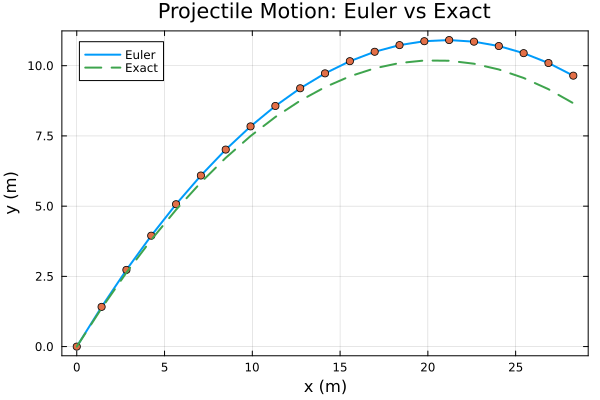

In [20]:
using Plots
r0 = [0.0, 0.0]
v0 = [speed * cos(angle), speed * sin(angle)]
exact_trajectory_x = Float64[]
exact_trajectory_y = Float64[]
for t in 0:dt:T
    push!(exact_trajectory_x, r0[1] + v0[1] * t + 0.5 * a[1] * t^2)
    push!(exact_trajectory_y, r0[2] + v0[2] * t + 0.5 * a[2] * t^2)
end
p = plot(title="Projectile Motion: Euler vs Exact",
         xlabel="x (m)", ylabel="y (m)", frame=:box)
p = plot!(p, trajectory_x, trajectory_y, label="Euler", lw=2)
p = scatter!(p, trajectory_x, trajectory_y, label=:none, lw=2)
p = plot!(p, exact_trajectory_x, exact_trajectory_y, label="Exact", lw=2, ls=:dash)
display(p)

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<figure>
<img src="../../assets/figures/week3-euler-trajectory.png" alt="image" />
<figcaption aria-hidden="true">image</figcaption>
</figure>
<p dir="rtl" style="text-align:right">يتبع المسار المرصود القطع المكافئ الدقيق عن قرب: تقع العلامات تقريبًا على المنحنى المتقطع عند كل زمن مرسوم. وعند <span dir="ltr" class="math inline">\(t=T\)</span> تقع عينة أويلر فوق النقطة الدقيقة بمقدار <span dir="ltr" class="math inline">\(gT\Delta t/2=0.981\)</span> م، وهو بالضبط القيمة التي يبلغ عنها جدول التنقيح أدناه لـ <span dir="ltr" class="math inline">\(\Delta t=0.1\)</span> ثانية. والعلامات المرسومة هي العينات المخزنة، لا منحنى أملس عبرها؛ والمنحنى عبر العلامات مجرد دليل بصري.</p>
<h2 id="التنقيح-المقارنة-مع-جواب-معلوم">التنقيح: المقارنة مع جواب معلوم</h2>
<p dir="rtl" style="text-align:right">بالنسبة لموضع ابتدائي <span dir="ltr" class="math inline">\(\mathbf r_0\)</span> وسرعة ابتدائية <span dir="ltr" class="math inline">\(\mathbf v_0\)</span>، الحركة الدقيقة تحت تسارع ثابت هي <span dir="ltr" class="math display">\[\mathbf r_{\rm exact}(t)=\mathbf r_0+\mathbf v_0 t+\tfrac12\mathbf a t^2.\]</span> لنشغّل التكامل نفسه لعدة خطوات زمنية، مع إبقاء <span dir="ltr" class="math inline">\(T/\Delta t\)</span> عددًا صحيحًا:</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>قبل التنفيذ:</strong> نتوقّع القيمة أو النص أو الرسم الموصوف أعلاه. هذا هو المثال المقابل من الفصل المكتوب.</p>
</div>

In [21]:
using LinearAlgebra
g = 9.81; speed = 20.0; angle = pi / 4; T = 2.0
r0 = [0.0, 0.0]
v0 = [speed * cos(angle), speed * sin(angle)]
a = [0.0, -g]
for dt in (0.2, 0.1, 0.05, 0.02)
    r = copy(r0); v = copy(v0)
    N = round(Int, T / dt)
    for step in 1:N
        r = r + v * dt
        v = v + a * dt
    end
    exact = r0 + v0 * T + 0.5 * a * T^2
    println("dt = $dt, error = ", round(norm(r - exact); digits=4), " m")
end

dt = 0.2, error = 1.962

 m
dt = 0.1, error = 0.981 m
dt = 0.05, error = 0.4905 m
dt = 0.02, error = 0.1962 m


<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right"><strong>تحقّق:</strong> نقارن النتيجة بالشرح الوارد أدناه. تعرض الخلية تلقائيًا تعبيرها الأخير فقط؛ أما <code dir="ltr">println</code> فتكتب النص عمدًا. نعيد تشغيل الخلايا السابقة عند تغيير أي مدخل.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">مخرجات مرجعية في الملاحظات المكتوبة (للمقارنة مع مخرجات الخلية الفعلية):</p>
<pre dir="ltr" style="text-align:left" class="text"><code dir="ltr">dt = 0.2, error = 1.962 m
dt = 0.1, error = 0.981 m
dt = 0.05, error = 0.4905 m
dt = 0.02, error = 0.1962 m</code></pre>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">تنصيف <span dir="ltr" class="math inline">\(\Delta t\)</span> ينصّف خطأ الموضع. وفي تسارع ثابت وأويلر صريح، تكون السرعة عند الأزمنة المتقطعة دقيقة حتى تقريب الفاصلة العائمة، بينما يحمل الموضع خطأً منهجيًا: <span dir="ltr" class="math display">\[\mathbf r_N-\mathbf r_{\rm exact}(T)=-\tfrac12\mathbf a\,T\Delta t.\]</span> في الجاذبية الهابطة، يقع المسار العددي <em>فوق</em> المسار الدقيق عند زمن ثابت، ومقدار الخطأ هو <span dir="ltr" class="math inline">\(gT\Delta t/2\)</span>، بالضبط القيم المطبوعة أعلاه.</p>
<p dir="rtl" style="text-align:right">لماذا يتدرج الخطأ مع <span dir="ltr" class="math inline">\(\Delta t\)</span>؟ يحذف كل تحديث موضع لأويلر الحد <span dir="ltr" class="math inline">\(\tfrac12 a(\Delta t)^2\)</span>، لذا يتناسب الخطأ الموضعي المحلي مع <span dir="ltr" class="math inline">\((\Delta t)^2\)</span>. ويوجد <span dir="ltr" class="math inline">\(N=T/\Delta t\)</span> خطوة. وفي هذا المثال ذي التسارع الثابت، تتراكم المساهمات المحذوفة بشكل متماسك، معطية خطأ عامًا يتناسب مع <span dir="ltr" class="math inline">\(N(\Delta t)^2=T\Delta t\)</span>. وهذا هو <em>التقارب من الرتبة الأولى</em>. والمحاكاة ليست الفيزياء الدقيقة، لكن الخطأ يتقلص بشكل متوقع، ويمكننا رؤيته يتقلص.</p>
<p dir="rtl" style="text-align:right"><strong>سؤال ختامي:</strong> ماذا يحدث للخطأ إذا جعلنا الخطوة الزمنية أصغر بعشر مرات؟ اختبروا ذلك عدديًا قبل الشرح.</p>
<h4 id="تكامل-من-رتبة-أعلى-نظرة-أولى-اختياري">تكامل من رتبة أعلى: نظرة أولى (اختياري)</h4>
<p dir="rtl" style="text-align:right">خطأ الرتبة الأولى لأويلر ليس نهاية القصة. فكرة أفضل: خذ نصف خطوة، وقدّر المشتقة عند نقطة المنتصف تلك، واستخدمها لاتخاذ الخطوة الكاملة: <span dir="ltr" class="math display">\[k_1=f(y_n),\qquad k_2=f(y_n+\tfrac12\Delta t\,k_1),\qquad
y_{n+1}=y_n+\Delta t\,k_2.\]</span> الطريقة التي تستخدم مشتقة واحدة في الفترة الوسطى هي طريقة من الرتبة الثانية؛ وفي تسارع ثابت تكون دقيقة بالصدفة. وأخذ عينات إضافية من المشتقة في مواضع ذكية يعطي رتبًا أعلى، حتى طريقة Runge–Kutta الكلاسيكية من الرتبة الرابعة (“RK4”). هذه الصيغ خلفية اختيارية، وليست شيئًا نحتاج إلى كتابته في هذا المقرر.</p>
<h2 id="تمرين-أول-زمن-تبريد-مرصود">تمرين: أول زمن تبريد مرصود</h2>
<p dir="rtl" style="text-align:right">نستخدم نموذج تبريد نيوتن، <span dir="ltr" class="math inline">\(\dot T=-k(T-T_{\rm room})\)</span>، لجسم ذي حرارة داخلية منتظمة تقريبًا في بيئة ثابتة. والمعدل <span dir="ltr" class="math inline">\(k&gt;0\)</span> بـ s<span dir="ltr" class="math inline">\(^{-1}\)</span>؛ ويمكن قياس فروق الحرارة بالكلفن أو بالدرجات المئوية. ونفترض أن فقد الحرارة يتناسب تقريبًا مع ذلك الفرق، لا أن النموذج يغطي التبخر أو تأثيرات إشعاعية كبيرة.</p>
<p dir="rtl" style="text-align:right">توفر دفتر التمرين التحديث الفيزيائي. ونحدد التهيئة والشرط والتحديث والعدّاد، ثم نستخدم حلقة <code dir="ltr">while</code> لإيجاد أول عينة عند العتبة أو أدنى منها. والمساواة تُعدّ وصولًا إلى العتبة. ونتنبأ بما يحدث إذا كانت العينة الابتدائية مؤهلة أصلًا، ولماذا لا يمكن بلوغ عتبة أدنى من حرارة الغرفة بتبريد رتيب من الأعلى. وبعد مناقشة 20 دقيقة نبدأ واجب المطرقة، الذي تتوقف حلقته عند أول عينة تحت الأرض.</p>
<h2 id="الواجب-الرئيسي-رمي-مطرقة-مع-مقاومة-هواء">الواجب الرئيسي: رمي مطرقة مع مقاومة هواء</h2>
<p dir="rtl" style="text-align:right">نحاكي رمي مطرقة ثنائي الأبعاد من الأصل مع مقاومة هواء تربيعية، ونخزّن تاريخها المرصود. النموذج لكل وحدة كتلة هو <span dir="ltr" class="math display">\[\dot x=v_x,\quad \dot y=v_y,\quad \dot v_x=-b v v_x,\quad
\dot v_y=-g-b v v_y,\qquad v=\sqrt{v_x^2+v_y^2},\]</span> حيث <span dir="ltr" class="math inline">\(g=9.81\)</span> m/s<span dir="ltr" class="math inline">\(^2\)</span> ومعامل سحب <span dir="ltr" class="math inline">\(b\approx0.001\)</span> m<span dir="ltr" class="math inline">\(^{-1}\)</span>. يقرأ البرنامج السرعة الابتدائية وزاوية الرمي بالدرجات والزمن الكلي <span dir="ltr" class="math inline">\(T\)</span> والخطوة الزمنية <span dir="ltr" class="math inline">\(\Delta t\)</span> و<span dir="ltr" class="math inline">\(b\)</span>، ثم يقدم الحالة بأويلر صريح ويخزّن تواريخ متطابقة لـ <span dir="ltr" class="math inline">\(x,y,v_x,v_y\)</span>. ويتوقف عند أول عينة مقترحة بشرط <span dir="ltr" class="math inline">\(y&lt;0\)</span>، أو بعد <span dir="ltr" class="math inline">\(T\)</span>، ويطبع المسافة الأفقية المقطوعة.</p>
<p dir="rtl" style="text-align:right">نرسم أولًا المسار المتوقع ونحدد الوحدات والإشارات. ثم نبني المتجهات والحلقة، مع الحرص على تحديث الموضع من السرعة القديمة. ونفحص التحديث الأول يدويًا ونتحقق من أن كل متجه ينمو بعنصر واحد في كل خطوة، وأن السرعة الأفقية تتحلل عبر السحب فقط، وأن التسارع العمودي يشمل الجاذبية وحد السحب معًا. ونشغّل البرنامج بالمثال المعطى، ونقارن المسافة المطبوعة بتقدير محسوب يدويًا، وننقّح <span dir="ltr" class="math inline">\(\Delta t\)</span> لنرى كيف تتحرك المسافة المرصودة. ونحفظ رسم المسار كأثر. ويجب أن يذكر التقرير القاعدة التي أوقفت الحلقة: عبور الأرض أو نهاية نافذة المحاكاة. والامتداد الاختياري في الورقة، الذي يختبر ما إذا كانت <span dir="ltr" class="math inline">\(45^\circ\)</span> ما زالت تعظم المدى، غير مطلوب. ويبقى تعريف الدوال مادة الأسبوع الخامس.</p>
<h2 id="مكافأة-اختيارية-ثلاث-صيغ-تكامل">مكافأة اختيارية: ثلاث صيغ تكامل</h2>
<p dir="rtl" style="text-align:right">هذه المكافأة اختيارية، وليست شرطًا مسبقًا لعمل لاحق، وليست مُختبرة. وهي تساوي <strong>ثلث نقطة في الدرجة النهائية</strong>.</p>
<p dir="rtl" style="text-align:right">نقارن أويلر الأمامي وأويلر-كرومر وصيغة velocity-Verlet (نقطة المنتصف) على سقوط حر بتتبع الطاقة الميكانيكية لكل وحدة كتلة. ونقرأ الزمن النهائي والخطوة الزمنية والارتفاع الابتدائي والسرعة الابتدائية، ونشغّل الصيغ الثلاث على الشبكة نفسها، ونطبع الطاقات النوعية النهائية الثلاث. ثم نرسم الطاقة النوعية مقابل الزمن للصيغ الثلاث مع القيمة المحفوظة الدقيقة. وسؤالان نظريان قصيران يطلبان اشتقاق تغير الطاقة في كل خطوة لكل صيغة وقول أي صيغة أفضل ولماذا.</p>
<h2 id="استكشاف-إضافي-من-مشية-واحدة-إلى-انتشار">استكشاف إضافي: من مشية واحدة إلى انتشار</h2>
<p dir="rtl" style="text-align:right">يمكن لمسار واحد أن ينجرف عائدًا نحو أصله. والانتشار عبارة عن مجموعة: بالنسبة لخطوات وحدة مستقلة وغير منحازة، يحقق الإزاحة المربعة المتوسطة <span dir="ltr" class="math inline">\(\langle r_n^2\rangle=n\)</span> بوحدات الشبكة، لأن حدود التقاطع تتلاشى في المتوسط. وإذا استغرقت الخطوة الواحدة <span dir="ltr" class="math inline">\(\tau\)</span> وكان طولها <span dir="ltr" class="math inline">\(\ell\)</span>، فإن معامل الانتشار ثنائي الأبعاد المقابل هو <span dir="ltr" class="math inline">\(D=\ell^2/(4\tau)\)</span>.</p>
<p dir="rtl" style="text-align:right">باستخدام وصفة مجموعة مُعطاة، نقارن مجموعة صغيرة وأخرى أكبر من المشيات، ونرسم الإزاحة المربعة المتوسطة مقابل رقم الخطوة، وندرس التقلبات حول الخط المستقيم المتوقع. ونشرح لماذا مربع متوسط الإزاحة كمية مختلفة ويمكن أن يظل قريبًا من الصفر. ونسجّل إعداد المولّد وحجم المجموعة مع الشكل. هذا الاستكشاف اختياري وغير مُختبر؛ والآلية المجموعية المُعطاة ليست شرطًا مسبقًا للعمل الأساسي.</p>
</div>

<div dir="rtl" style="text-align:right">
<h2 id="أمثلة-صغيرة-وفحوص-مذكورة-في-الفصل">أمثلة صغيرة وفحوص مذكورة في الفصل</h2>
<p dir="rtl" style="text-align:right">تجعل الخلايا التالية الأمثلة المضمّنة والفحوص المحلولة في الفصل قابلة للتنفيذ. وهي لا تضيف حلولًا للواجب.</p>
</div>

<div dir="rtl" style="text-align:right">
<p dir="rtl" style="text-align:right">يقارن النص خطوتين زمنيتين بهبوط تحليلي. نعيد حلقة المتجهات عند كل خطوة زمنية؛ ولا حاجة إلى تعريف دالة.</p>
</div>

In [22]:
for timestep in [0.05, 0.025]
    times = [0.0]; xs = [0.0]; ys = [1.0]
    vys = [10.0 * sind(45.0)]
    while ys[end] > 0.0
        push!(times, times[end] + timestep)
        push!(xs, xs[end] + 10.0 * cosd(45.0) * timestep)
        push!(ys, ys[end] + vys[end] * timestep)
        push!(vys, vys[end] - 9.81 * timestep)
    end
    println("dt=", timestep, ": t=", round(times[end]; digits=2),
            " s; range=", round(xs[end]; digits=4), " m")
end
vy0 = 10.0 * sind(45.0)
analytic_time = (vy0 + sqrt(vy0^2 + 2 * 9.81)) / 9.81
println("analytic: t=", round(analytic_time; digits=5),
        " s; range=", round(10.0 * cosd(45.0) * analytic_time; digits=4), " m")

dt=0.05: t=1.65 s; range=11.6673 m
dt=0.025: t=1.6 s; range=11.3137 m
analytic: t=1.57135 s; range=11.1111 m


<div dir="rtl" style="text-align:right">
<h2 id="الختام-والتأمل">الختام والتأمل</h2>
<p dir="rtl" style="text-align:right">نشرح نتيجة واحدة بالكلمات، ونذكر وحداتها أو افتراضاتها حين يلزم، ونحدّد فحصًا قد يكشف خطأ. تصف فقرات التمرين والواجب والمكافأة الاختيارية والاستزادة أعلاه الخطوات التالية. لا تصبح الخلفية الاختيارية شرطًا للامتحان.</p>
</div>